# 1. Data

The data are not distributed with this repository;
`download()` fetches a public copy of the official release and verifies it
(see the README).

In [1]:
from fico_xml import data

data.download()
raw = data.load_raw()
raw.shape

(10459, 24)

A few applicants (the target and the first features):

In [2]:
raw.iloc[:5, :8]

,RiskPerformance,ExternalRiskEstimate,MSinceOldestTradeOpen,MSinceMostRecentTradeOpen,AverageMInFile,NumSatisfactoryTrades,NumTrades60Ever2DerogPubRec,NumTrades90Ever2DerogPubRec
0,Bad,55,144,4,84,20,3,0
1,Bad,61,58,15,41,2,4,4
2,Bad,67,66,5,24,9,0,0
3,Bad,66,169,1,73,28,1,1
4,Bad,81,333,27,132,12,0,0


The classes are almost balanced:

In [3]:
raw[data.TARGET].value_counts()

RiskPerformance
Bad     5459
Good    5000
Name: count, dtype: int64

## The features

Every feature comes with a description in the official data dictionary and
a *monotonicity constraint*, i.e., the direction in which it should influence
the risk, for example, more overdue accounts should not make an applicant less
risky.
The plain-English labels are used in the explanations.

In [4]:
import pandas as pd

meta = data.feature_metadata()
pd.set_option('display.max_colwidth', 90)
pd.DataFrame(meta['features']).T[['description', 'label', 'monotonicity']]

,description,label,monotonicity
ExternalRiskEstimate,Consolidated version of risk markers,external risk estimate,Monotonically Decreasing
MSinceOldestTradeOpen,Months Since Oldest Trade Open,number of months since the oldest credit account was opened,Monotonically Decreasing
MSinceMostRecentTradeOpen,Months Since Most Recent Trade Open,number of months since the most recent credit account was opened,Monotonically Decreasing
AverageMInFile,Average Months in File,average age of the credit accounts in months,Monotonically Decreasing
NumSatisfactoryTrades,Number Satisfactory Trades,number of credit accounts in good standing,Monotonically Decreasing
NumTrades60Ever2DerogPubRec,Number Trades 60+ Ever,number of credit accounts that were ever 60 or more days overdue,Monotonically Increasing
NumTrades90Ever2DerogPubRec,Number Trades 90+ Ever,number of credit accounts that were ever 90 or more days overdue,Monotonically Increasing
PercentTradesNeverDelq,Percent Trades Never Delinquent,percentage of credit accounts that were never overdue,Monotonically Decreasing
MSinceMostRecentDelq,Months Since Most Recent Delinquency,number of months since the most recent overdue payment,Monotonically Decreasing
MaxDelq2PublicRecLast12M,"Max Delq/Public Records Last 12 Months. See tab ""MaxDelq"" for each category",worst payment delay in the last 12 months,Values 0-7 are monotonically decreasing


The two delinquency features are categorical;
their codes follow the data dictionary:

In [5]:
pd.DataFrame({f: pd.Series(meta['features'][f]['categories'])
              for f in ('MaxDelqEver', 'MaxDelq2PublicRecLast12M')})

,MaxDelqEver,MaxDelq2PublicRecLast12M
0,NaN,derogatory comment
1,no such value,120+ days delinquent
2,derogatory comment,90 days delinquent
3,120+ days delinquent,60 days delinquent
4,90 days delinquent,30 days delinquent
5,60 days delinquent,unknown delinquency
6,30 days delinquent,unknown delinquency
7,unknown delinquency,current and never delinquent
8,current and never delinquent,all other
9,all other,all other


## Special values

Instead of missing values, the data use three special codes:

In [6]:
meta['special_values']

{'-9': 'No Bureau Record or No Investigation',
 '-8': 'No Usable/Valid Trades or Inquiries',
 '-7': 'Condition not Met (e.g. No Inquiries, No Delinquencies)'}

How often each of them occurs:

In [7]:
features = raw[data.FEATURES]
special = pd.DataFrame({code: (features == code).sum() for code in (-9, -8, -7)})
special[special.sum(axis=1) > 0]

,-9,-8,-7
ExternalRiskEstimate,598,0,0
MSinceOldestTradeOpen,588,239,0
MSinceMostRecentTradeOpen,588,0,0
AverageMInFile,588,0,0
NumSatisfactoryTrades,588,0,0
NumTrades60Ever2DerogPubRec,588,0,0
NumTrades90Ever2DerogPubRec,588,0,0
PercentTradesNeverDelq,588,0,0
MSinceMostRecentDelq,588,176,4664
MaxDelq2PublicRecLast12M,588,0,0


The -9 code is special:
588 applicants have it for **every** feature;
there is no credit record at all, so they cannot be assessed automatically.
Apart from these, -9 is rare.

In [8]:
no_record = (features == -9).all(axis=1)
int(no_record.sum()), int((features[~no_record] == -9).any(axis=1).sum())

(588, 10)

## Baselines

Before building any model it helps to know what simple rules achieve.
Always predicting the most common class gives:

In [9]:
from fico_xml import evaluation

evaluation.majority_baseline(raw[data.TARGET])

{'accuracy': 0.5219428243617936, 'F1 (Good)': 0.0}

The *external risk estimate* -- i.e., a consolidated risk score included in
the data -- is a strong predictor on its own;
the best threshold on it gives:

In [10]:
score = raw['ExternalRiskEstimate'].where(~no_record)
threshold = evaluation.best_threshold(score, raw[data.TARGET])
threshold, evaluation.threshold_baseline(score[~no_record], raw[data.TARGET][~no_record], threshold)

(74.0, {'accuracy': 0.708844088744808, 'F1 (Good)': 0.6819389110225763})

The proportion of `Good` applicants rises with the external risk estimate:

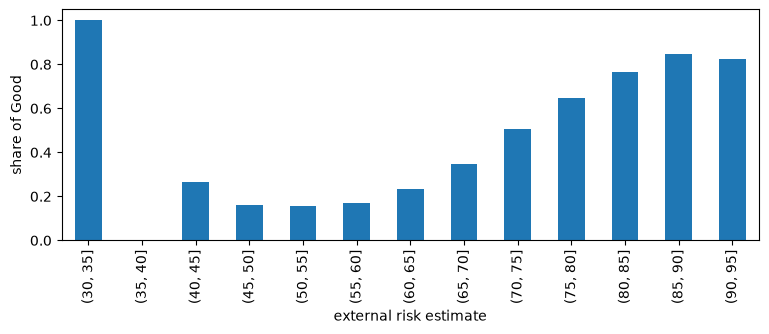

In [11]:
import matplotlib.pyplot as plt

bins = pd.cut(score, range(30, 101, 5))
share = (raw[data.TARGET] == 'Good').groupby(bins, observed=True).mean()
ax = share.plot.bar(figsize=(9, 3), xlabel='external risk estimate', ylabel='share of Good')

## Delinquency and the outcome

How the worst payment delay ever and the number of accounts in good standing
relate to the outcome (applicants with a credit record):

In [12]:
with_record = raw[~no_record]
worst = with_record['MaxDelqEver'].astype(str).map(meta['features']['MaxDelqEver']['categories'])
pd.crosstab(worst, with_record[data.TARGET], normalize='index').round(2)

RiskPerformance,Bad,Good
MaxDelqEver,,
120+ days delinquent,0.62,0.38
30 days delinquent,0.60,0.40
60 days delinquent,0.66,0.34
90 days delinquent,0.67,0.33
current and never delinquent,0.40,0.60
derogatory comment,0.70,0.30
unknown delinquency,0.42,0.58


In [13]:
satisfactory = pd.cut(with_record['NumSatisfactoryTrades'], [-1, 5, 10, 20, 30, 100])
pd.crosstab(satisfactory, with_record[data.TARGET], normalize='index').round(2)

RiskPerformance,Bad,Good
NumSatisfactoryTrades,,
"(-1, 5]",0.78,0.22
"(5, 10]",0.62,0.38
"(10, 20]",0.53,0.47
"(20, 30]",0.47,0.53
"(30, 100]",0.44,0.56


Applicants who were never delinquent and those with many accounts in good
standing are more often `Good` -- as the monotonicity constraints suggest --
but neither feature separates the classes on its own.